# Módulo 1 — Exemplo prático de Machine Learning
**Dataset:** Titanic (Kaggle)  
**Objetivo:** Exploração, pré-processamento e classificação binária  
**Autor:** Marcel Teixeira Chiarelo  
**Orientador:** Prof. Dr. Rodrigo Sanches Miani  
**Coorientador:** Gustavo Di Giovanni  
**Data:** junho/2026

In [22]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

In [23]:
url = "https://raw.githubusercontent.com/datasciencedojo/datasets/master/titanic.csv"
df = pd.read_csv(url)
df.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


## Análise Exploratória
Nesta seção, exploramos as características básicas do dataset para entender sua estrutura, tipos de dados e distribuição das classes.

Dimensões: (891, 12)

Tipos de dados:
PassengerId      int64
Survived         int64
Pclass           int64
Name            object
Sex             object
Age            float64
SibSp            int64
Parch            int64
Ticket          object
Fare           float64
Cabin           object
Embarked        object
dtype: object

Valores ausentes por coluna:
PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64

Distribuição da variável alvo (Survived):
Survived
0    549
1    342
Name: count, dtype: int64


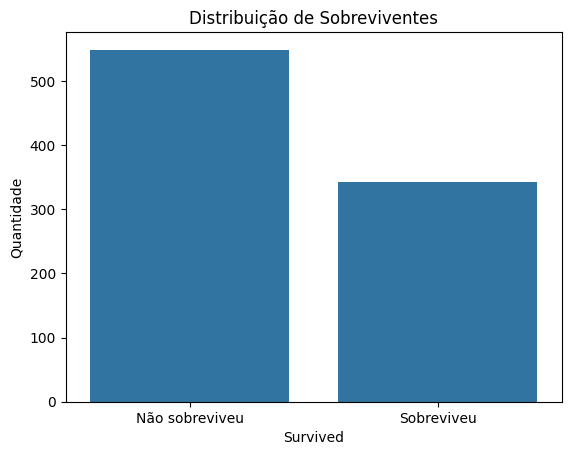

In [24]:
# Dimensões do dataset
print("Dimensões:", df.shape)

# Tipos de cada coluna
print("\nTipos de dados:")
print(df.dtypes)

# Valores ausentes
print("\nValores ausentes por coluna:")
print(df.isnull().sum())

# Distribuição das classes
print("\nDistribuição da variável alvo (Survived):")
print(df['Survived'].value_counts())

# Gráfico de distribuição
sns.countplot(x='Survived', data=df)
plt.title('Distribuição de Sobreviventes')
plt.xticks([0, 1], ['Não sobreviveu', 'Sobreviveu'])
plt.ylabel('Quantidade')
plt.show()

## Pré-processamento
Removemos colunas irrelevantes, tratamos valores ausentes e codificamos variáveis categóricas para preparar os dados para o modelo.

In [25]:
# Remover colunas irrelevantes
df = df.drop(columns=['Name', 'Ticket', 'Cabin', 'PassengerId', 'Embarked'])

# Preencher valores ausentes em Age com a mediana
df['Age'] = df['Age'].fillna(df['Age'].median())

# Codificar Sex como 0/1
df['Sex'] = df['Sex'].map({'male': 0, 'female': 1})

# Separar features e rótulo
X = df.drop(columns=['Survived'])
y = df['Survived']

# Confirmar resultado
print("Features:", list(X.columns))
print("Dimensões de X:", X.shape)
print("Distribuição de y:")
print(y.value_counts())

Features: ['Pclass', 'Sex', 'Age', 'SibSp', 'Parch', 'Fare']
Dimensões de X: (891, 6)
Distribuição de y:
Survived
0    549
1    342
Name: count, dtype: int64


## Divisão Treino/Teste
Dividimos os dados em 80% para treino e 20% para teste, mantendo a proporção das classes com stratify.

In [26]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Tamanho do treino:", X_train.shape)
print("Tamanho do teste:", X_test.shape)
print("\nDistribuição no treino:")
print(y_train.value_counts())
print("\nDistribuição no teste:")
print(y_test.value_counts())

Tamanho do treino: (712, 6)
Tamanho do teste: (179, 6)

Distribuição no treino:
Survived
0    439
1    273
Name: count, dtype: int64

Distribuição no teste:
Survived
0    110
1     69
Name: count, dtype: int64


## Treinamento do Modelo
Treinamos uma Árvore de Decisão (Decision Tree), um algoritmo clássico de classificação supervisionada, sobre os dados de treino.

In [27]:
modelo = DecisionTreeClassifier(random_state=42)
modelo.fit(X_train, y_train)

print("Modelo treinado com sucesso!")
print("Profundidade da árvore:", modelo.get_depth())
print("Número de folhas:", modelo.get_n_leaves())

Modelo treinado com sucesso!
Profundidade da árvore: 23
Número de folhas: 162


## Avaliação do Modelo
Avaliamos o modelo usando métricas por classe: precisão, revocação e F1-score. Também geramos a matriz de confusão para visualizar os erros.

Relatório de Classificação:
                precision    recall  f1-score   support

Não sobreviveu       0.83      0.87      0.85       110
    Sobreviveu       0.78      0.71      0.74        69

      accuracy                           0.81       179
     macro avg       0.80      0.79      0.80       179
  weighted avg       0.81      0.81      0.81       179



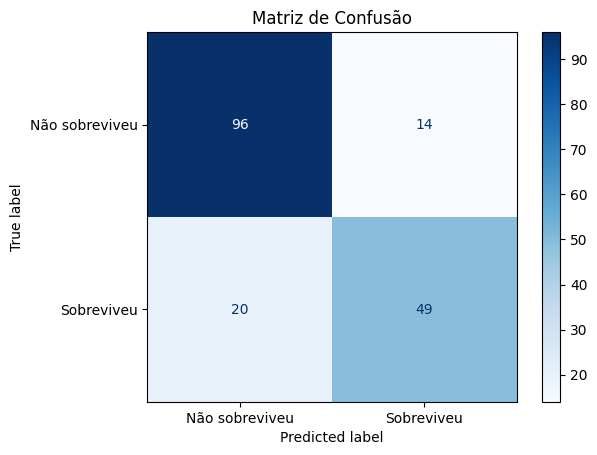

In [28]:
# Predições
y_pred = modelo.predict(X_test)

# Relatório de classificação
print("Relatório de Classificação:")
print(classification_report(y_test, y_pred, target_names=['Não sobreviveu', 'Sobreviveu']))

# Matriz de confusão
cm = confusion_matrix(y_test, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['Não sobreviveu', 'Sobreviveu'])
disp.plot(cmap='Blues')
plt.title('Matriz de Confusão')
plt.show()